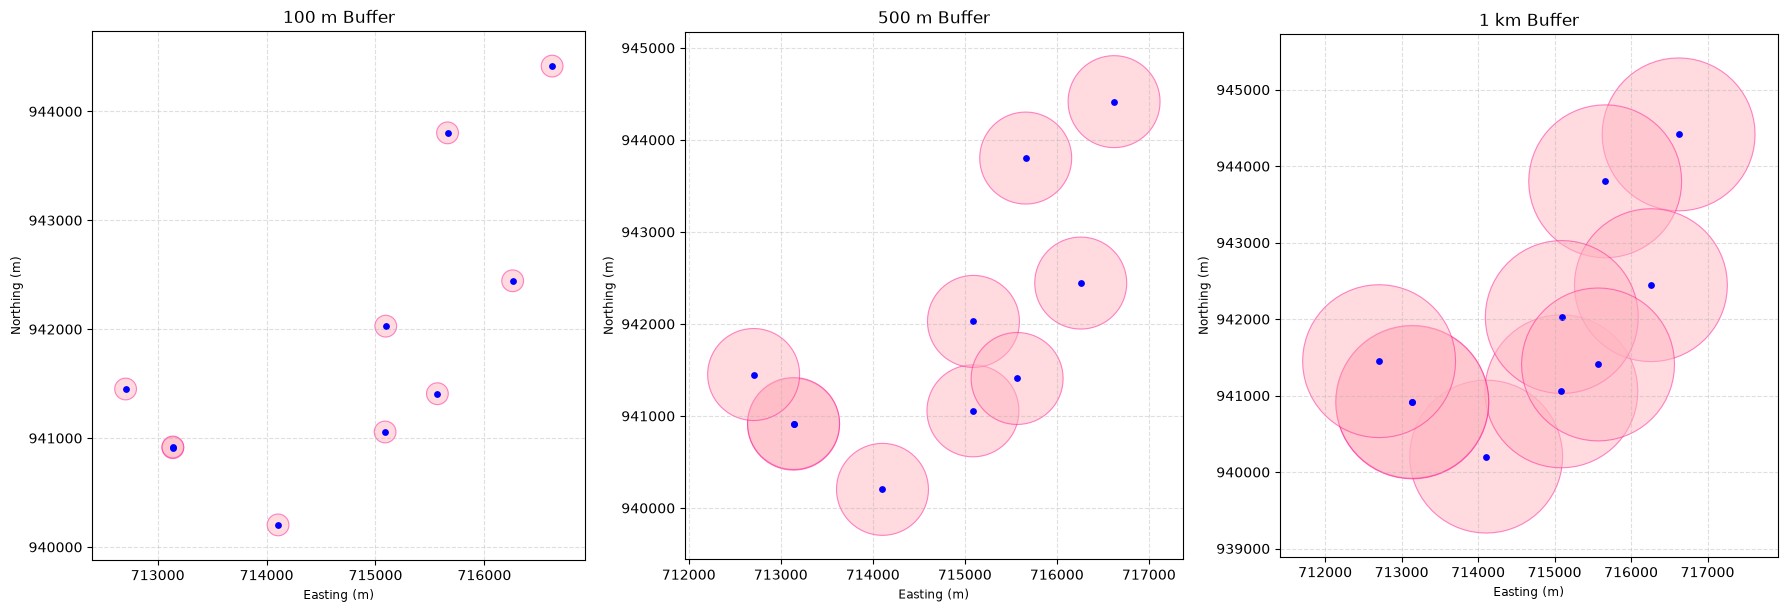

In [ ]:
#1
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

np.random.seed(42)

n = 10

center_lon = 76.95
center_lat = 8.52

longitudes = center_lon + np.random.uniform(-0.02, 0.02, n)
latitudes = center_lat + np.random.uniform(-0.02, 0.02, n)

points = [Point(lon, lat) for lon, lat in zip(longitudes, latitudes)]

gdf = gpd.GeoDataFrame(
    {"point_id": range(1, n + 1)},
    geometry=points,
    crs="EPSG:4326"
)

gdf = gdf.to_crs("EPSG:32643")

buffers_100 = gdf.copy()
buffers_100["geometry"] = gdf.geometry.buffer(100)

buffers_500 = gdf.copy()
buffers_500["geometry"] = gdf.geometry.buffer(500)

buffers_1000 = gdf.copy()
buffers_1000["geometry"] = gdf.geometry.buffer(1000)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

buffer_data = [
    (buffers_100, 100, "100 m Buffer"),
    (buffers_500, 500, "500 m Buffer"),
    (buffers_1000, 1000, "1 km Buffer")
]

for ax, (buffer_gdf, distance, title) in zip(axes, buffer_data):
    buffer_gdf.plot(
    ax=ax,
    color="lightpink",
    alpha=0.5,
    edgecolor="deeppink",
    linewidth=0.8
)

    gdf.plot(
        ax=ax,
        color="blue",
        markersize=15
    )

    ax.set_title(title)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.set_aspect("equal")
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


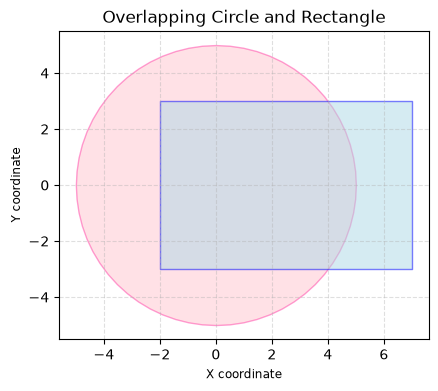

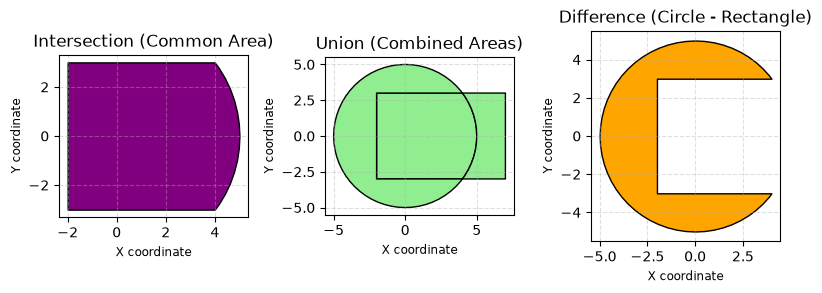

Circle area: 78.41371226364852
Rectangle area: 54.0
Intersection area: 40.061564729900034
Union area: 92.35214753374848
Difference area: 38.352147533748465


In [ ]:
#2
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, box

# Point (0, 0) with a radius of 5 units
circle = Point(0, 0).buffer(5)

# Rectangle from (-2, -3) to (7, 3)
rectangle = box(-2, -3, 7, 3)

# Create GeoDataFrames
circle_gdf = gpd.GeoDataFrame(
    {"name": ["Circle"]},
    geometry=[circle],
    crs="EPSG:32643"
)

rectangle_gdf = gpd.GeoDataFrame(
    {"name": ["Rectangle"]},
    geometry=[rectangle],
    crs="EPSG:32643"
)

fig, ax = plt.subplots(figsize=(6, 4))

circle_gdf.plot(
    ax=ax, color="lightpink",
    edgecolor="deeppink", alpha=0.4
)

rectangle_gdf.plot(
    ax=ax, color="lightblue",
    edgecolor="blue", alpha=0.5
)

ax.set_title("Overlapping Circle and Rectangle")
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.4)

plt.show()

# Overlay operations
intersection = gpd.overlay(
    circle_gdf, rectangle_gdf, how="intersection"
)

union = gpd.overlay(
    circle_gdf, rectangle_gdf, how="union"
)

difference = gpd.overlay(
    circle_gdf, rectangle_gdf, how="difference"
)

# Plot overlay results
fig, axes = plt.subplots(1, 3, figsize=(8, 6))

intersection.plot(
    ax=axes[0], color="purple", edgecolor="black"
)
axes[0].set_title("Intersection (Common Area)")

union.plot(
    ax=axes[1], color="lightgreen", edgecolor="black"
)
axes[1].set_title("Union (Combined Areas)")

difference.plot(
    ax=axes[2], color="orange", edgecolor="black"
)
axes[2].set_title("Difference (Circle - Rectangle)")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

print("Circle area:", circle.area)
print("Rectangle area:", rectangle.area)
print("Intersection area:", intersection.geometry.area.sum())
print("Union area:", union.geometry.area.sum())
print("Difference area:", difference.geometry.area.sum())


In [ ]:
#3
import os
os.environ["GDAL_DATA"] = r"C:\Users\aparn\anaconda3\envs\geo\Library\share\gdal"
import geopandas as gpd

folder = r"C:\Users\aparn\MTech26\Lab6\nedumangad"

for root, dirs, files in os.walk(folder):
    for file in files:
        if file.endswith(".shp"):

            path = os.path.join(root, file)

            gdf = gpd.read_file(path)

            print("Shapefile:", file)
            print("Projection:", gdf.crs)
            print("-----------------------------")




Shapefile: nedumangad_boundary.shp
Projection: EPSG:4326
-----------------------------
Shapefile: nedumangad_buildings.shp
Projection: EPSG:32644
-----------------------------
Shapefile: nedumangad_landuse.shp
Projection: EPSG:32643
-----------------------------
Shapefile: nedumangad_pois.shp
Projection: None
-----------------------------
Shapefile: nedumangad_road.shp
Projection: EPSG:32644
-----------------------------
Shapefile: nedumangad_waterways.shp
Projection: EPSG:32644
-----------------------------
Shapefile: buildings_within_100m_stream.shp
Projection: EPSG:32643
-----------------------------


In [ ]:

import geopandas as gpd

lulc = r"C:\Users\aparn\MTech26\Lab6\nedumangad\landuse\nedumangad_landuse.shp"
gdf = gpd.read_file(lulc)

print("Columns in LULC shapefile:")
print(gdf.columns.tolist())
classes = gdf["fclass"].unique().tolist()

print("Number of unique classes:", len(classes))
print(classes)

forest_count = (
    gdf["fclass"]
    .astype("string")
    .str.strip()
    .str.casefold()
    .eq("forest")
    .sum()
)

print("Number of forest features:", forest_count)


Columns in LULC shapefile:
['osm_id', 'code', 'fclass', 'name', 'geometry']
Number of unique classes: 14
['recreation_ground', 'residential', 'park', 'grass', 'forest', 'quarry', 'industrial', 'farmland', 'commercial', 'retail', 'scrub', 'nature_reserve', 'farmyard', 'orchard']
Number of forest features: 53


In [26]:
roads = r"C:\Users\aparn\MTech26\Lab6\nedumangad\roads\nedumangad_road.shp"
gdf = gpd.read_file(roads)
print("Columns in Roads shapefile:")
print(gdf.columns.tolist())
tunnel_count = (gdf["tunnel"] == "T").sum()
print("Number of tunnels:", int(tunnel_count))


Columns in Roads shapefile:
['fid', 'osm_id', 'code', 'fclass', 'name', 'ref', 'oneway', 'maxspeed', 'layer', 'bridge', 'tunnel', 'geometry']
Number of tunnels: 6


In [34]:
boundary = r"C:\Users\aparn\MTech26\Lab6\nedumangad\nedumangad_boundary.shp"
gdf = gpd.read_file(boundary)
boundary_projected = gdf.copy()
boundary_projected = boundary_projected.to_crs(epsg=32643)
area_km2 = boundary_projected.geometry.area.sum() / 1_000_000

print(f"Area of Nedumangad: {area_km2:.2f} km²")

Area of Nedumangad: 918.44 km²


In [46]:
bp = r"C:\Users\aparn\MTech26\Lab6\nedumangad\buildings\nedumangad_buildings.shp"
roads = r"C:\Users\aparn\MTech26\Lab6\nedumangad\roads\nedumangad_road.shp"
water = r"C:\Users\aparn\MTech26\Lab6\nedumangad\waterways\nedumangad_waterways.shp"
pois = r"C:\Users\aparn\MTech26\Lab6\nedumangad\pois\nedumangad_pois.shp"
lulc = r"C:\Users\aparn\MTech26\Lab6\nedumangad\landuse\nedumangad_landuse.shp"

b = gpd.read_file(bp)
r = gpd.read_file(roads)
w = gpd.read_file(water)
p = gpd.read_file(pois)
l = gpd.read_file(lulc)

In [47]:
# CRS correction (preprocessing)
# Make sure to run this cell strictly once, if you run it multiple times bounds will be inf

b = b.set_crs("EPSG:4326", allow_override=True)   # rewrite the metadata
b = b.to_crs("EPSG:32643")                        # actually transform it

r = r.set_crs("EPSG:4326", allow_override=True)
r = r.to_crs("EPSG:32643")

w = w.set_crs("EPSG:4326", allow_override=True)
w = w.to_crs("EPSG:32643")

p = p.set_crs("EPSG:4326", allow_override=True)
p = p.to_crs("EPSG:32643")

l = l.set_crs("EPSG:4326", allow_override=True)
l = l.to_crs("EPSG:32643")

print(b.crs)
print(b.total_bounds)

print(w.crs)
print(w.total_bounds)

print(r.crs)
print(r.total_bounds)

print(p.crs)
print(p.total_bounds)

print(l.crs)
print(l.total_bounds)
     

EPSG:32643
[704003.58646088 939834.14877419 742030.83238092 977372.81694622]
EPSG:32643
[704241.87975757 939832.07635188 743696.1012696  977132.53209224]
EPSG:32643
[704035.02920147 939684.8188251  743735.57661122 977372.92306555]
EPSG:32643
[705026.92781164 939990.77603993 739916.55228779 977365.13194876]
EPSG:32643
[704751.63720743 939949.74427294 745233.30367806 977370.97675543]


Total Buildings within 200 m from river:  1782
Building names (any 10): 
 9         Pazhavadi Ganapathy Temple
75                        Indian Oil
89     Fast Track Court, Nedumangadu
99                               NaN
100                              NaN
101                              NaN
102                              NaN
103                              NaN
104                              NaN
105                              NaN
Name: name, dtype: str


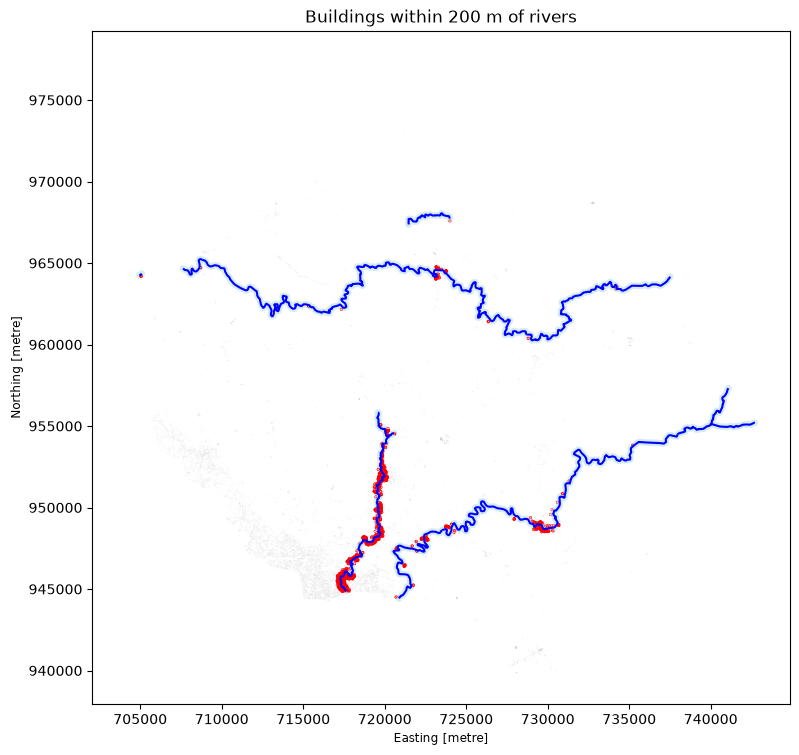

In [69]:
#4
rivers =w[w["fclass"].isin(["river"])]
river_buffer =  gpd.GeoDataFrame(geometry=[rivers.buffer(200).union_all()],
                                 crs = "EPSG:32643")
e = gpd.sjoin(b,river_buffer,predicate="intersects",
              how="inner")

print("Total Buildings within 200 m from river: ", len(e))
print("Building names (any 10): \n", e["name"].head(10))

ax=river_buffer.plot(color="lightblue", alpha=0.5, figsize=(9, 9))
b.plot(ax=ax,color="lightgrey")
e.plot(ax=ax ,facecolor="red", edgecolor="red", linewidth=2)
rivers.plot(ax=ax,color="blue")
plt.title("Buildings within 200 m of rivers"); plt.show()

Total hospital-matching features: 54
Hospitals within 750 m of primary roads: 26
Hospital names (up to 10):
                         Venad Hospital
                     Ayurvedic Hospital
                DPMS Hospital Karakulam
       RIMS Hospital  (not functioning)
           Karunya Hospital, Pothencode
   Government Homoeo Hospital Karakulam
        Nedumangadu Government Hospital
Government Ayurveda Hospital Nedumangad
                           V J Hospital
       Vetenary Hospital, Paruthippally


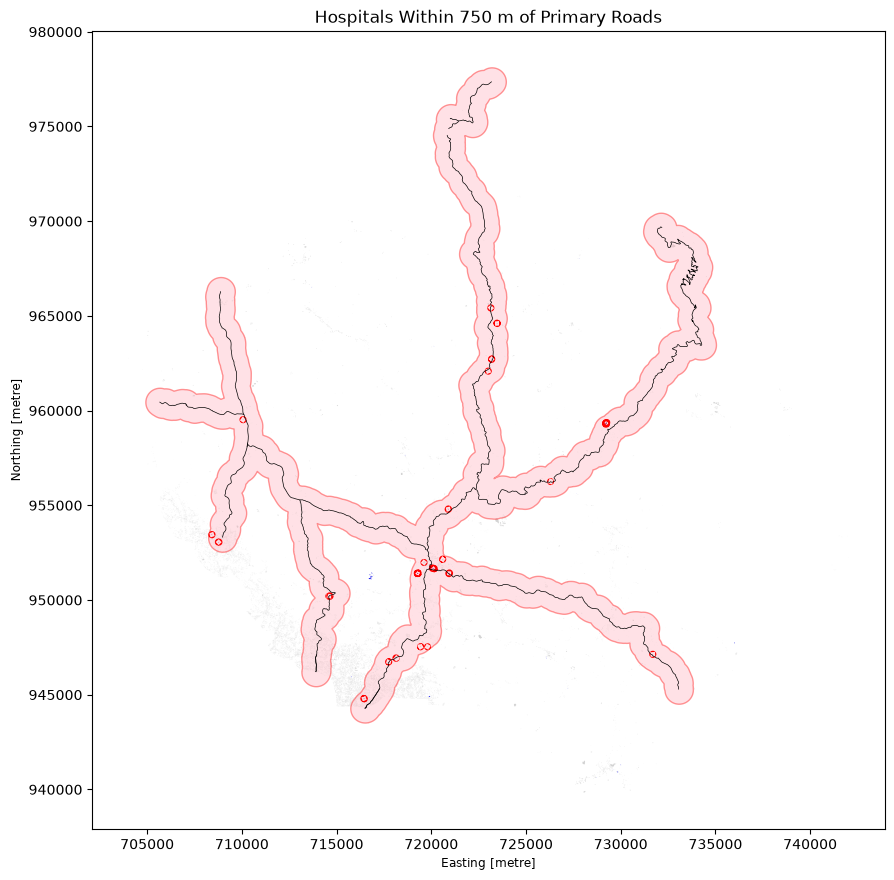

In [ ]:
#5
import geopandas as gpd
import matplotlib.pyplot as plt

bh = b[
    b["name"].astype("string").str.contains(
        "hospital", case=False, na=False
    )
].copy()

roads = r[r["fclass"] == "primary"].copy()

roads_buffer = gpd.GeoDataFrame(
    geometry=[roads.geometry.buffer(750).union_all()],
    crs = "EPSG:32643"
)

# Find hospitals intersecting the road buffer
e = gpd.sjoin(
    bh,
    roads_buffer,
    predicate="intersects",
    how="inner"
)

# Print results
print("Total hospital-matching features:", len(bh))
print("Hospitals within 750 m of primary roads:", len(e))
print("Hospital names (up to 10):")
print(e["name"].head(10).to_string(index=False))

# Plot results
fig, ax = plt.subplots(figsize=(9, 9))

# All buildings
b.plot(ax=ax, color="lightgrey", edgecolor="none")

# Road buffer
roads_buffer.plot(
    ax=ax, color="lightpink", edgecolor="red", alpha=0.4
)

# All hospital-matching features
bh.plot(ax=ax, color="blue", linewidth=5)

# Hospitals within the buffer
if not e.empty:
    e.plot(ax=ax ,facecolor="red", edgecolor="red", linewidth=5)

# Primary roads
roads.plot(ax=ax, color="black", linewidth=0.5)

ax.set_title("Hospitals Within 750 m of Primary Roads")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


In [83]:
#6
bridges = r[r["bridge"].isin(["T"])]
rivers = w[w["fclass"].isin(["river","canals"])]

e = gpd.overlay(rivers,bridges,how="intersection",keep_geom_type=False)

print("Total no of bridges : ", len(bridges))
print("Total bridges on top of river: ", len(e))
print("Bridge names (any 20): \n", e["name_2"].head(len(e)))


Total no of bridges :  606
Total bridges on top of river:  52
Bridge names (any 20): 
 0                                               MC Road
1                                                   NaN
2                           Vamanapuram Aramthanam Road
3                                                   NaN
4                                                   NaN
5                                                   NaN
6                                                   NaN
7                     Kallara-Muthuvila-Nedumagadu Road
8                          Nedumangad - Shorlacode Road
9                                      koovakudi bridge
10                                                  NaN
11                                                  NaN
12                                                  NaN
13                    Netta Bridge (Old Rajapatha Road)
14                                   LIC - Netta Bridge
15                                       Mulamukku Road
16               

In [ ]:
#7

import geopandas as gpd

forest = l[l["fclass"] == "forest"].copy()
roads_selected = r[r["fclass"].isin(["primary", "tertiary"])].copy()
roads_in_forest = gpd.sjoin(
    roads_selected,
    forest,
    predicate="intersects",
    how="inner"
)
print("\nNumber of roads in forest:", len(roads_in_forest))
print("Road names inside forest areas:")


print(
    roads_in_forest[["name_left","fclass_left"]]
    .dropna(subset=["name_left"])
    .drop_duplicates()
    .to_string(index=False)
)

print(
    "Road records with names:",
    roads_in_forest["name_left"].notna().sum()
)

print(
    "Road records without names:",
    roads_in_forest["name_left"].isna().sum()
)



Number of roads in forest: 7
Road names inside forest areas:
                         name_left fclass_left
MEENMOOD KUTTIMOOD PUTHANKADA ROAD    tertiary
 Thiruvananthapuram - Ponmudi Road     primary
           Vithura - Bonacaud Road    tertiary
Total road records in forest: 7
Road records with names: 6
Road records without names: 1
